# Figure 5: double-descent peak on Pile token statistics

Camera-ready version of Figure 5 (`fig:pile-peak`, Section 8). The first cells draw the figure from `peak_location_results.npz` and recompute the peak locations from the stored loss curves: $D=1231$ (sparse) and $610$ (dense) at $N=600$, $D=3046$ and $1160$ at $N=1200$, against $K(D)=N$ at $D=1208$ and $3184$. Nothing else is recomputed.

The figure shows $N=1200$ at its printed size, $2.75\times1.9$ in (`0.5\textwidth`): tick labels 7 pt, axis labels 8 pt, legend and in-plot labels 7 pt.

The cells under *Experiment* are the peak-location experiment that writes `peak_location_results.npz` (Pythia tokenizer, a 10,000-document sample of the Pile, CPU, about 20 minutes). The file in this folder is from the rerun of 6 Nov 2026; its peaks match the printed outputs below exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.transforms as mtransforms

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "mathtext.fontset": "dejavusans",
                     "pdf.fonttype": 42})

# Printed sizes (pt); the figure is drawn at its size on the page
FIG_W, FIG_H = 2.75, 1.9          # inches
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND = 7, 8, 9, 7

def style(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=FS_LABEL, labelpad=1)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=1)
    ax.tick_params(which="both", labelsize=FS_TICK, pad=1.5)
    ax.tick_params(which="major", length=2.5)
    ax.tick_params(which="minor", length=1.5)

gmean = lambda Y: np.exp(np.log(Y).mean(0))                       # geometric mean over seeds
gse   = lambda Y: gmean(Y) * np.log(Y).std(0) / np.sqrt(Y.shape[0])
slope = lambda x, Y: -np.polyfit(np.log(np.asarray(x, float)), np.log(Y).mean(0), 1)[0]

In [2]:
# Peak locations, recomputed from the stored loss curves (same rule as the experiment below)
z = np.load("peak_location_results.npz")
Dgrid, K_meas = z["Dgrid"].astype(float), z["K_meas"]
Kinv = lambda k: float(np.exp(np.interp(np.log(k), np.log(K_meas), np.log(Dgrid))))   # D at which K(D) = k

def find_peak(D, L):
    """Local maximum relative to neighbours, interior points only."""
    q = L[1:-1] / np.maximum(L[:-2], L[2:])
    return int(D[1:-1][int(np.argmax(q))]), float(q.max())

print(f"{'N':>6}{'design':>8}{'peak D':>8}{'prediction':>12}{'peak/pred':>11}")
for N in z["N_LIST"]:
    for tag, pred in (("sparse", Kinv(N)), ("dense", float(N))):
        pk, _ = find_peak(z[f"{N}_{tag}_D"], z[f"{N}_{tag}_L"])
        print(f"{N:6d}{tag:>8}{pk:8d}{pred:12.0f}{pk/pred:11.3f}")

     N  design  peak D  prediction  peak/pred
   600  sparse    1231        1208      1.019
   600   dense     610         600      1.017
  1200  sparse    3046        3184      0.957
  1200   dense    1160        1200      0.967


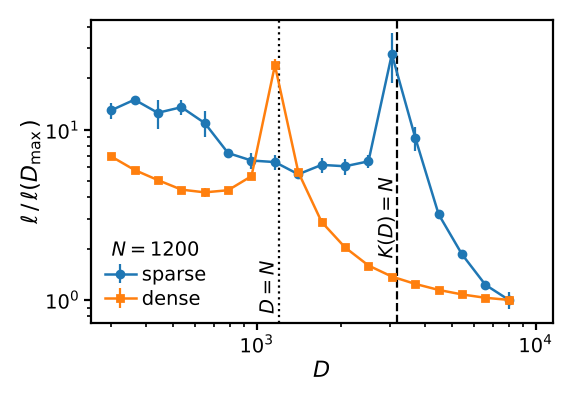

In [3]:
# FIGURE 5: loss vs D at N = 1200, sparse design and dense baseline
N = 1200
D_cov = Kinv(N)
fig5, ax = plt.subplots(figsize=(FIG_W, FIG_H), layout="constrained")
for tag, color, fmt in (("sparse", "C0", "o-"), ("dense", "C1", "s-")):
    D, L, se = z[f"{N}_{tag}_D"], z[f"{N}_{tag}_L"], z[f"{N}_{tag}_se"]
    ax.errorbar(D, L / L[-1], se / L[-1], fmt=fmt, color=color, ms=2.5, lw=0.9,
                elinewidth=0.8, capsize=0, label=tag)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(right=1.15e4)                      # so that 10^4 is labelled
ax.axvline(N, ls=":", c="k", lw=0.8)
ax.axvline(D_cov, ls="--", c="k", lw=0.8)
blend = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
ax.text(N, 0.03, "$D=N$", fontsize=FS_LEGEND, ha="right", va="bottom", rotation=90, transform=blend)
ax.text(D_cov, 1.75, "$K(D)=N$", fontsize=FS_LEGEND, ha="right", va="bottom", rotation=90)
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
style(ax, "$D$", r"$\ell\,/\,\ell(D_{\max})$")
ax.legend(title=f"$N={N}$", loc="lower left", fontsize=FS_LEGEND, title_fontsize=FS_LEGEND,
          frameon=False, handletextpad=0.3, borderaxespad=0.3, labelspacing=0.25, handlelength=1.6)
fig5.savefig("../figures/Figure5.pdf")
fig5.savefig("../figures/Figure5.png", dpi=300)
plt.show()

## Experiment

The original experiment notebook, kept as run. Its printed outputs are from that run; the figure above does not depend on running these cells.

# Coverage-limited scaling on natural-language activation statistics

Anonymous supplementary code.

**Claim under test.** In a sparse-activation model the data-side bottleneck is
$K(D)$, the number of coordinates observed at least once in $D$ samples, rather
than $D$ itself. Two accounts therefore place the double-descent peak of a
fixed-$N$ model differently as $D$ is swept:

| account | peak at |
|---|---|
| standard / dense | $D = N$ |
| coverage | $K(D) = N$ |

**Design.** The sparse arm takes its activation mask from real tokenized text.
A dense control is matched on the marginal variance spectrum. The two arms use
identically distributed targets ($w$ i.i.d. standard normal in both), the same
class of Gaussian random feature map, and the same min-norm solver, but these
are drawn independently rather than shared. $K(D)$ is obtained by counting
distinct active coordinates; no power-law exponent is fitted anywhere.

**Scope.** The activation mask and its frequency structure are
measured from text (a 10k-document sample of the Pile); the amplitude spectrum
is imposed; the target is synthetic ($y=w^\top x$, $w$ i.i.d. flat).

**On reading $\alpha_1$ off the coverage curve.** $\beta = d\log K/d\log D$ is not
constant over the measured range: it is pinned near 1 at small $D$, where almost
every token is new, and driven toward 0 as the vocabulary fills. Any $\alpha_1$
inferred from $\beta$ alone is therefore window-dependent (roughly 0.27-0.40
here). The peak-location estimates in Cells 4-5 do not depend on this choice.

**Runtime.** CPU only, roughly 20 minutes end to end.

In [ ]:
# CELL 1 -- configuration and feature construction
!pip install -q datasets transformers
import numpy as np, matplotlib.pyplot as plt
from scipy import sparse
from datasets import load_dataset
from transformers import AutoTokenizer

SEED      = 0
TOKENIZER = "EleutherAI/pythia-70m-deduped"
DATASET   = "NeelNanda/pile-10k"
CHUNK     = 1          # tokens per sample; 1 = unigram indicator
N_SAMPLES = 1_000_000
V_CAP     = 4_000      # vocabulary truncation; controls saturation and cost
ALPHA2    = 0.3        # imposed amplitude exponent
rng = np.random.default_rng(SEED)

tk = AutoTokenizer.from_pretrained(TOKENIZER)
ids = []
for d in load_dataset(DATASET, split="train"):
    ids.extend(tk(d["text"], truncation=True, max_length=2048).input_ids)
    if len(ids) > CHUNK * N_SAMPLES:
        break
ids   = np.array(ids)
VOCAB = max(len(tk), int(ids.max()) + 1)

cnt   = np.bincount(ids, minlength=VOCAB)
keep  = np.argsort(-cnt)[:V_CAP]
remap = -np.ones(VOCAB, dtype=np.int64); remap[keep] = np.arange(V_CAP)
ids   = remap[ids]

ids  = ids[:(len(ids)//CHUNK)*CHUNK].reshape(-1, CHUNK)
rows = np.repeat(np.arange(ids.shape[0]), CHUNK)
ok   = ids.ravel() >= 0
A = sparse.csr_matrix((np.ones(ok.sum()), (rows[ok], ids.ravel()[ok])),
                      shape=(ids.shape[0], V_CAP))
A.sum_duplicates(); A.data[:] = 1.0
A = A[np.asarray((A != 0).sum(1)).ravel() > 0].tocsr()
n_all, M = A.shape
print(f"samples={n_all}  M={M}  L0={A.nnz/n_all:.2f}")

config.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/373 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/921 [00:00<?, ?B/s]

data/train-00000-of-00001-4746b8785c874c(…): reconstructing file:   0%|          |  0.00B / 33.3MB            

data/train-00000-of-00001-4746b8785c874c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10000 [00:00<?, ? examples/s]

samples=784549  M=4000  L0=1.00


       D     K(D)     K/D    K/M    beta
     100       73    0.73   0.02   0.997
     180      131    0.73   0.03   0.886
     322      205    0.64   0.05   0.797
     579      332    0.57   0.08   0.820
    1039      536    0.52   0.13   0.783
    1866      829    0.44   0.21   0.718
    3351     1243    0.37   0.31   0.652
    6016     1780    0.30   0.44   0.571
   10802     2427    0.22   0.61   0.472
   19395     3091    0.16   0.77   0.347
   34824     3642    0.10   0.91   0.203
   62528     3922    0.06   0.98   0.079
  112269     3995    0.04   1.00   0.017
  201580     4000    0.02   1.00   0.001
  361939     4000    0.01   1.00   0.000
  649867     4000    0.01   1.00   0.000

beta over unsaturated coverage-limited range: 0.790
NOTE K(D)<D requires fewer than one new coordinate per sample on average;
     this is the scope condition for the coverage bottleneck.


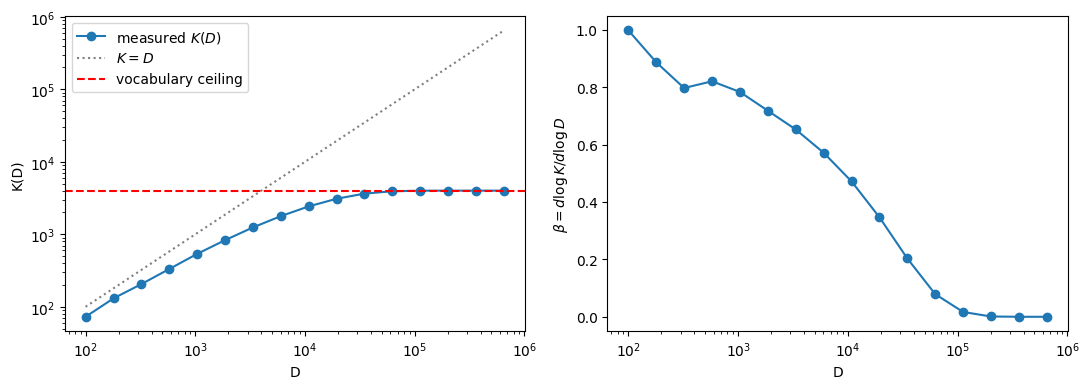

In [ ]:
# CELL 2 -- coverage curve K(D), measured by counting
perm = rng.permutation(n_all)
n_te = min(20_000, n_all // 5)
Xte, Xtr = A[perm[:n_te]], A[perm[n_te:]]
n_tr = Xtr.shape[0]
p_j  = np.asarray((Xtr != 0).sum(0)).ravel() / n_tr

def K_measured(D, reps=4):
    return float(np.mean([
        (np.asarray((Xtr[rng.choice(n_tr, D, replace=False)] != 0).sum(0)).ravel() > 0).sum()
        for _ in range(reps)]))

Dgrid  = np.unique(np.round(np.logspace(2, np.log10(0.85*n_tr), 16)).astype(int))
K_meas = np.array([K_measured(int(d)) for d in Dgrid])
beta   = np.gradient(np.log(K_meas), np.log(Dgrid))

K_of = lambda d: np.exp(np.interp(np.log(d), np.log(Dgrid), np.log(K_meas)))
Kinv = lambda k: np.exp(np.interp(np.log(k), np.log(K_meas), np.log(Dgrid)))

print(f"{'D':>8}{'K(D)':>9}{'K/D':>8}{'K/M':>7}{'beta':>8}")
for d, k, b in zip(Dgrid, K_meas, beta):
    print(f"{d:8d}{k:9.0f}{k/d:8.2f}{k/M:7.2f}{b:8.3f}")

sel = (K_meas/M < 0.5) & (K_meas/Dgrid < 1)
print(f"\nbeta over unsaturated coverage-limited range: {np.median(beta[sel]):.3f}")
print("NOTE K(D)<D requires fewer than one new coordinate per sample on average;")
print("     this is the scope condition for the coverage bottleneck.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(Dgrid, K_meas, 'o-', label='measured $K(D)$')
ax[0].loglog(Dgrid, Dgrid, ':', c='gray', label='$K=D$')
ax[0].axhline(M, ls='--', c='r', label='vocabulary ceiling')
ax[0].set(xlabel='D', ylabel='K(D)'); ax[0].legend()
ax[1].semilogx(Dgrid, beta, 'o-')
ax[1].set(xlabel='D', ylabel=r'$\beta=d\log K/d\log D$')
plt.tight_layout(); plt.show()

In [ ]:
# CELL 3 -- amplitude spectrum, target, and matched dense control
rank_by_freq = np.argsort(-p_j)
amp = np.zeros(M)
amp[rank_by_freq] = np.arange(1, M + 1) ** (-(ALPHA2 + 1) / 2)

Xtr_w = Xtr.multiply(amp[None, :]).tocsr()
Xte_w = Xte.multiply(amp[None, :]).tocsr()
w     = rng.standard_normal(M)                 # flat i.i.d. target
ytr_w = np.asarray(Xtr_w @ w).ravel()
yte_w = np.asarray(Xte_w @ w).ravel()

# dense control: identical M and identical marginal variance spectrum
vd = np.sort(np.asarray(Xtr_w.multiply(Xtr_w).mean(0)).ravel())[::-1]
print(f"variance spectrum matched over M={M} coordinates")
print(f"sparse L0={Xtr_w.nnz/n_tr:.2f}   dense L0={M}")

variance spectrum matched over M=4000 coordinates
sparse L0=1.00   dense L0=4000


In [ ]:
# CELL 4 -- peak-location experiment
# Both arms use the SAME dense Gaussian random feature map and the same solver.
N_LIST, SEEDS, RCOND = [600, 1200], 4, 1e-10
D_MAX = int(min(n_tr, 8000))

def loss_sparse(N, D, s):
    r = np.random.default_rng(s)
    u = r.standard_normal((N, M)) / np.sqrt(N)
    idx = r.choice(n_tr, D, replace=False)
    th, *_ = np.linalg.lstsq(np.asarray(Xtr_w[idx] @ u.T), ytr_w[idx], rcond=RCOND)
    return float(np.mean((yte_w - np.asarray(Xte_w @ u.T) @ th) ** 2))

_cache = {}
def loss_dense(N, D, s):
    if s not in _cache:
        r = np.random.default_rng(s + 7777); sd = np.sqrt(vd)
        _cache[s] = (r.standard_normal((D_MAX, M)) * sd,
                     r.standard_normal((3000, M)) * sd,
                     r.standard_normal(M))
    X, Xt, wd = _cache[s]
    u = np.random.default_rng(s * 31 + N).standard_normal((N, M)) / np.sqrt(N)
    th, *_ = np.linalg.lstsq(X[:D] @ u.T, X[:D] @ wd, rcond=RCOND)
    return float(np.mean((Xt @ wd - (Xt @ u.T) @ th) ** 2))

def find_peak(D, L):
    """Local maximum relative to neighbours, interior points only."""
    q = L[1:-1] / np.maximum(L[:-2], L[2:])
    return int(D[1:-1][int(np.argmax(q))]), float(q.max())

results = {}
for N in N_LIST:
    Dp = np.unique(np.round(np.logspace(np.log10(0.25*N), np.log10(D_MAX), 18)).astype(int))
    D_cov = float(Kinv(N))
    print(f"\nN={N} | standard predicts D={N} | coverage predicts D={D_cov:.0f}"
          f" | separation {D_cov/N:.2f}x")
    for tag, f in (("sparse", loss_sparse), ("dense", loss_dense)):
        Lall = np.array([[f(N, int(d), s) for s in range(SEEDS)] for d in Dp])
        L = Lall.mean(1)
        pk, prom = find_peak(Dp, L)
        results[(N, tag)] = dict(D=Dp, L=L, se=Lall.std(1)/np.sqrt(SEEDS),
                                 peak=pk, prom=prom, D_cov=D_cov)
        print(f"  {tag:7s} peak D={pk:6d}  prominence={prom:5.2f}"
              f"  peak/N={pk/N:5.2f}  peak/D_cov={pk/D_cov:5.2f}")

np.savez("peak_location_results.npz",
         **{f"{n}_{t}_{k}": v for (n, t), r in results.items()
            for k, v in r.items() if k in ("D", "L", "se")},
         Dgrid=Dgrid, K_meas=K_meas, p_j=p_j, N_LIST=N_LIST)
print("\nsaved peak_location_results.npz")


N=600 | standard predicts D=600 | coverage predicts D=1208 | separation 2.01x
  sparse  peak D=  1231  prominence= 8.89  peak/N= 2.05  peak/D_cov= 1.02
  dense   peak D=   610  prominence= 8.83  peak/N= 1.02  peak/D_cov= 0.51

N=1200 | standard predicts D=1200 | coverage predicts D=3184 | separation 2.65x
  sparse  peak D=  3046  prominence= 3.09  peak/N= 2.54  peak/D_cov= 0.96
  dense   peak D=  1160  prominence= 4.24  peak/N= 0.97  peak/D_cov= 0.36

saved peak_location_results.npz


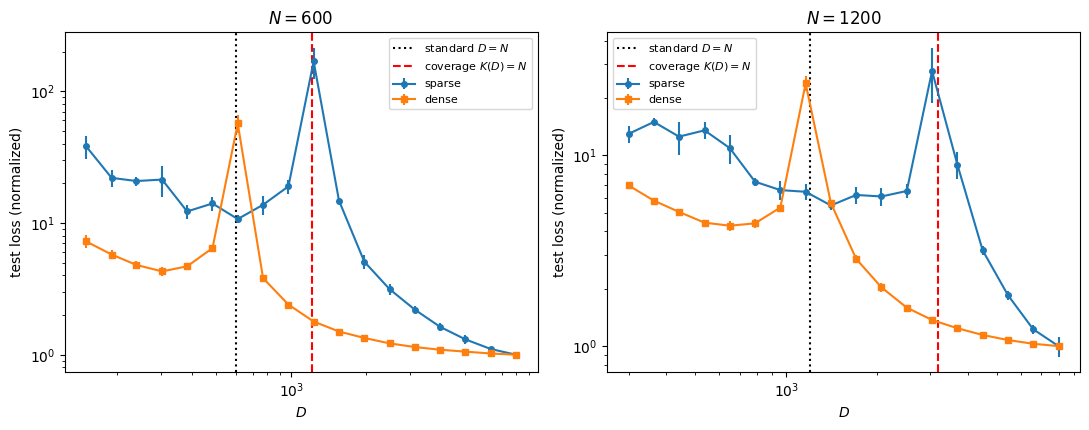

     N      arm   peak D     D=N   K(D)=N  peak/N  peak/cov
   600    dense      610     600     1208    1.02      0.51
   600   sparse     1231     600     1208    2.05      1.02
  1200    dense     1160    1200     3184    0.97      0.36
  1200   sparse     3046    1200     3184    2.54      0.96

Prediction: dense peak tracks D=N; sparse peak tracks K(D)=N.
Across N the dense peak should scale as N, the sparse peak as N^(1+a1).
  dense   d log D_peak / d log N = 0.93   (expect 1.00)
  sparse  d log D_peak / d log N = 1.31   (expect 1.27)


In [ ]:
# CELL 5 -- figure and summary
fig, axs = plt.subplots(1, len(N_LIST), figsize=(5.5*len(N_LIST), 4.4), squeeze=False)
for ax, N in zip(axs[0], N_LIST):
    for tag, c, mk in (("sparse", "C0", "o-"), ("dense", "C1", "s-")):
        r = results[(N, tag)]
        ax.errorbar(r["D"], r["L"]/r["L"][-1], r["se"]/r["L"][-1],
                    fmt=mk, color=c, label=tag, ms=4)
    ax.axvline(N, ls=':', c='k', label=r'standard $D=N$')
    ax.axvline(results[(N, "sparse")]["D_cov"], ls='--', c='r',
               label=r'coverage $K(D)=N$')
    ax.set(xscale='log', yscale='log', xlabel='$D$',
           ylabel='test loss (normalized)', title=f'$N={N}$')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("peak_location.pdf", bbox_inches="tight"); plt.show()

print(f"{'N':>6}{'arm':>9}{'peak D':>9}{'D=N':>8}{'K(D)=N':>9}{'peak/N':>8}{'peak/cov':>10}")
for N in N_LIST:
    for tag in ("dense", "sparse"):
        r = results[(N, tag)]
        print(f"{N:6d}{tag:>9}{r['peak']:9d}{N:8d}{r['D_cov']:9.0f}"
              f"{r['peak']/N:8.2f}{r['peak']/r['D_cov']:10.2f}")

print("\nPrediction: dense peak tracks D=N; sparse peak tracks K(D)=N.")
print("Across N the dense peak should scale as N, the sparse peak as N^(1+a1).")
if len(N_LIST) >= 2:
    lo, hi = min(N_LIST), max(N_LIST)
    for tag in ("dense", "sparse"):
        s = (np.log(results[(hi, tag)]['peak']) - np.log(results[(lo, tag)]['peak'])) \
            / (np.log(hi) - np.log(lo))
        print(f"  {tag:7s} d log D_peak / d log N = {s:.2f}"
              + ("   (expect 1.00)" if tag == "dense" else
                 f"   (expect {1/np.median(beta[sel]):.2f})"))

## Appendix: scope condition on learned sparse features

Optional, requires a GPU and `sae-lens`. Establishes that a sparse autoencoder
with $L_0 \approx 59$ admits no coverage-limited window: $K(D) > D$ throughout,
because each token activates many features at once. Supports the scope
condition stated in Cell 2.

```python
p = sae_stats.active[0] / sae_stats.n_tokens
p = p[p > 0]
Ds = np.logspace(1, np.log10(0.25 * sae_stats.n_tokens), 12)
K  = np.array([(1 - (1 - p) ** d).sum() for d in Ds])
b  = np.gradient(np.log(K), np.log(Ds))
for d, k, bb in zip(Ds, K, b):
    print(f"{d:8.0f} {k:9.0f} {k/d:7.2f} {k/p.size:7.2f} {bb:7.3f}")
```

A low $\beta$ is only meaningful where $K/M$ is small; near the dictionary
ceiling $\beta \to 0$ for reasons unrelated to sparsity.